In [8]:
import random
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
# import category_encoders as ce
import time
import warnings
warnings.filterwarnings('ignore')

In [9]:

num_records = 40428967
sample_size = 3500000
skip_values = sorted(random.sample(range(1,num_records), num_records - sample_size))

df_train = pd.read_csv("./kaggle/train.csv",skiprows=skip_values,nrows=sample_size)
df_train['hour'] = pd.to_datetime(df_train['hour'], format='%y%m%d%H')
df_train.head()

,id,click,hour,C1,banner_pos,site_id,site_domain,site_category,app_id,app_domain,...,device_type,device_conn_type,C14,C15,C16,C17,C18,C19,C20,C21
0,10000949271186029916,1,2014-10-21,1005,0,1fbe01fe,f3845767,28905ebd,ecad2386,7801e8d9,...,1,2,15707,320,50,1722,0,35,-1,79
1,10003585669470236873,0,2014-10-21,1005,0,d9750ee7,98572c79,f028772b,ecad2386,7801e8d9,...,1,0,17914,320,50,2043,2,39,-1,32
2,10004181428767727519,0,2014-10-21,1005,1,0c2fe9d6,27e3c518,28905ebd,ecad2386,7801e8d9,...,1,0,6558,320,50,571,2,39,-1,32
3,10010485868773711631,0,2014-10-21,1005,0,1fbe01fe,f3845767,28905ebd,ecad2386,7801e8d9,...,1,0,15701,320,50,1722,0,35,100084,79
4,10011085150831357375,0,2014-10-21,1005,0,1fbe01fe,f3845767,28905ebd,ecad2386,7801e8d9,...,1,0,15699,320,50,1722,0,35,-1,79


In [10]:

df_train['dayofweek'] = df_train['hour'].dt.dayofweek
df_train['hour_time'] = df_train['hour'].dt.hour

df_train.drop('hour',axis=1,inplace=True)

0    0.830158
1    0.169842
Name: click, dtype: float64




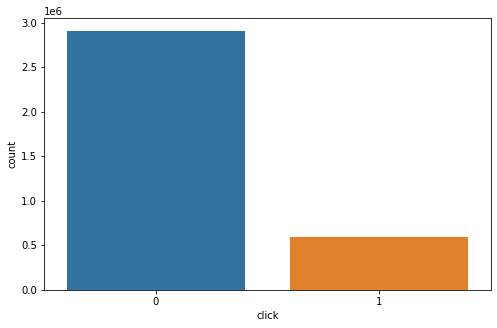

In [11]:

print(df_train.click.value_counts(normalize = True))
print('\n')
plt.figure(figsize=(8,5))
sns.countplot(x='click', data=df_train)
plt.show()


Text(0.5, 1.05, 'Pearson correlation of Features')

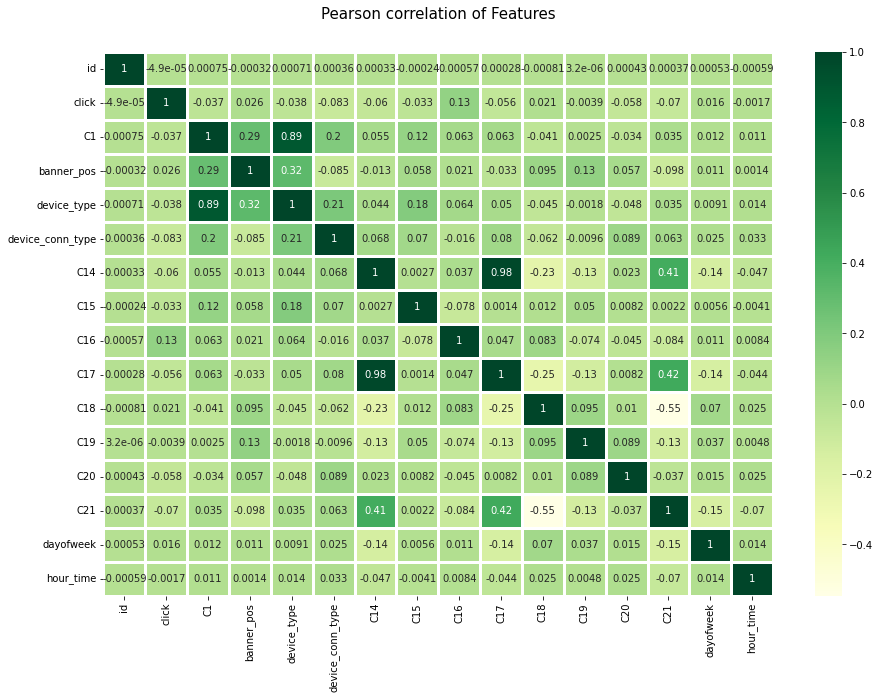

In [12]:

df_numer = df_train.select_dtypes(include=np.number)

corr = df_numer.corr()
f, ax = plt.subplots(figsize=(15,10))
sns.heatmap(corr, ax=ax, annot=True,linewidths=3,cmap='YlGn')
plt.title("Pearson correlation of Features", y=1.05, size=15)




In [13]:
df_train.drop(['C17','C1','C20'],inplace=True,axis=1)
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3500000 entries, 0 to 3499999
Data columns (total 22 columns):
 #   Column            Dtype 
---  ------            ----- 
 0   id                uint64
 1   click             int64 
 2   banner_pos        int64 
 3   site_id           object
 4   site_domain       object
 5   site_category     object
 6   app_id            object
 7   app_domain        object
 8   app_category      object
 9   device_id         object
 10  device_ip         object
 11  device_model      object
 12  device_type       int64 
 13  device_conn_type  int64 
 14  C14               int64 
 15  C15               int64 
 16  C16               int64 
 17  C18               int64 
 18  C19               int64 
 19  C21               int64 
 20  dayofweek         int64 
 21  hour_time         int64 
dtypes: int64(12), object(9), uint64(1)
memory usage: 587.5+ MB


In [28]:
X = df_train.iloc[:,2:]
y = df_train.iloc[:,1]

Original dataset shape  Counter({0: 2905554, 1: 594446})
Resampled dataset shape Counter({0: 594446, 1: 594446})


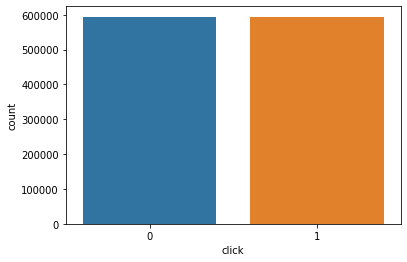

In [29]:
from imblearn.under_sampling import RandomUnderSampler

randomsample = RandomUnderSampler()
x_bal, y_bal = randomsample.fit_resample(X, y)

from collections import Counter
print('Original dataset shape  {}'.format(Counter(y)))
print('Resampled dataset shape {}'.format(Counter(y_bal)))
plt.figure()
sns.countplot(data=pd.DataFrame({'click:y_bal'}),x=y_bal)
plt.show()

In [30]:
x_bal.reset_index()
x_bal_len = len(x_bal)
x_bal_len

1188892

In [31]:
# merge the balanced data
x_bal = pd.DataFrame(x_bal)
y_bal = pd.DataFrame(y_bal)
df_bal = pd.concat([x_bal,y_bal],axis=1)
df_bal.head()

,banner_pos,site_id,site_domain,site_category,app_id,app_domain,app_category,device_id,device_ip,device_model,...,device_conn_type,C14,C15,C16,C18,C19,C21,dayofweek,hour_time,click
3027669,1,e151e245,7e091613,f028772b,ecad2386,7801e8d9,07d7df22,a99f214a,ad20244a,49ea3580,...,0,22759,320,50,2,35,23,2,14,0
858489,1,e4d8dd7b,a17bde68,3e814130,ecad2386,7801e8d9,07d7df22,a99f214a,e9620aad,684581ce,...,0,21912,320,50,0,35,221,3,3,0
739206,1,5b4d2eda,16a36ef3,f028772b,ecad2386,7801e8d9,07d7df22,a99f214a,6f71095c,1f0bc64f,...,0,21878,320,50,0,35,221,2,17,0
1085231,0,d6137915,bb1ef334,f028772b,ecad2386,7801e8d9,07d7df22,a99f214a,a94e897a,76dc4769,...,0,16920,320,50,0,431,117,3,17,0
3460869,0,85f751fd,c4e18dd6,50e219e0,9c13b419,2347f47a,f95efa07,a99f214a,88662252,1c6a881d,...,2,23161,320,50,0,47,221,3,19,0


In [32]:
# remove rows that banner_pos count is less than 100

#count the banner_pos
df_bal['banner_pos'].value_counts()


0    844861
1    341563
7      1696
2       320
4       264
5       134
3        54
Name: banner_pos, dtype: int64

In [33]:
# keep rows that are 0, 1, 7
df_bal = df_bal[df_bal['banner_pos'] != 2]
df_bal = df_bal[df_bal['banner_pos'] != 3]
df_bal = df_bal[df_bal['banner_pos'] != 4]
df_bal = df_bal[df_bal['banner_pos'] != 5]
df_bal = df_bal[df_bal['banner_pos'] != 6]

df_bal['banner_pos'].value_counts()

0    844861
1    341563
7      1696
Name: banner_pos, dtype: int64

In [34]:
# group the data by banner_pos and sample n reocords from each group
df_bal = df_bal.groupby('banner_pos').apply(lambda x: x.sample(n=500,random_state=42))
df_bal.reset_index(drop=True,inplace=True)
df_bal

,banner_pos,site_id,site_domain,site_category,app_id,app_domain,app_category,device_id,device_ip,device_model,...,device_conn_type,C14,C15,C16,C18,C19,C21,dayofweek,hour_time,click
0,0,85f751fd,c4e18dd6,50e219e0,92f5800b,ae637522,0f2161f8,a99f214a,86d1f4b5,054c8edf,...,3,21189,320,50,1,161,71,6,13,0
1,0,6a96a6d8,2ee3ecd0,3e814130,ecad2386,7801e8d9,07d7df22,a99f214a,1c74c384,89416188,...,0,20362,320,50,0,39,157,2,8,1
2,0,2b1ddb24,98acf46c,3e814130,ecad2386,7801e8d9,07d7df22,a99f214a,7a328e9f,7abbbd5c,...,0,17239,320,50,3,39,23,4,17,0
3,0,517b8671,ac5abf20,f028772b,ecad2386,7801e8d9,07d7df22,a99f214a,48422d73,ff5cbc87,...,0,19878,320,50,0,679,48,6,20,1
4,0,5b08c53b,7687a86e,3e814130,ecad2386,7801e8d9,07d7df22,a99f214a,c855f59d,711ee120,...,0,17654,300,250,2,39,33,6,11,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1495,7,85f751fd,c4e18dd6,50e219e0,5325bfcf,7801e8d9,0f2161f8,c5c19314,3562769c,34d5fa08,...,3,21791,320,480,3,1059,68,2,1,1
1496,7,85f751fd,c4e18dd6,50e219e0,941f1635,7801e8d9,0f2161f8,48816f80,d6181742,a8d2c4cf,...,2,21791,320,480,3,1059,68,3,19,1
1497,7,85f751fd,c4e18dd6,50e219e0,941f1635,7801e8d9,0f2161f8,d3d4bb4d,a202c705,7abbbd5c,...,2,21791,320,480,3,1059,68,3,15,1
1498,7,85f751fd,c4e18dd6,50e219e0,75076517,7801e8d9,0f2161f8,a8125989,70c4f73d,9e6d3278,...,2,22611,320,480,0,1059,110,0,8,1


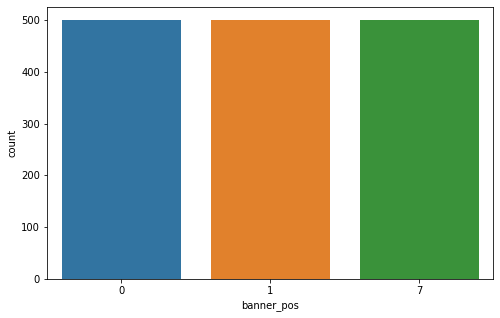

In [35]:
# check the distribution of banner_pos
plt.figure(figsize=(8,5))
sns.countplot(x='banner_pos', data=df_bal)
plt.show()



In [36]:
# write the balanced data to csv
df_bal.to_csv('./kaggle/balanced_data.csv',index=False)

In [40]:
df_bal.columns

Index(['banner_pos', 'site_id', 'site_domain', 'site_category', 'app_id',
       'app_domain', 'app_category', 'device_id', 'device_ip', 'device_model',
       'device_type', 'device_conn_type', 'C14', 'C15', 'C16', 'C18', 'C19',
       'C21', 'dayofweek', 'hour_time', 'click'],
      dtype='object')

In [41]:
# keep these columns: 'banner_pos', 'C14', 'C15', 'C16', 'C18', 'C19','C21', 'dayofweek', 'hour_time', 'click'
df_bal = df_bal[['banner_pos', 'C14', 'C15', 'C16', 'C18', 'C19','C21', 'dayofweek', 'hour_time', 'click']]
df_bal.head()

,banner_pos,C14,C15,C16,C18,C19,C21,dayofweek,hour_time,click
0,0,21189,320,50,1,161,71,6,13,0
1,0,20362,320,50,0,39,157,2,8,1
2,0,17239,320,50,3,39,23,4,17,0
3,0,19878,320,50,0,679,48,6,20,1
4,0,17654,300,250,2,39,33,6,11,1


In [42]:
# change the banner_pos name to 'selected_arm' and change 'click' to 'CTR_Lable'ArithmeticError
df_bal.rename(columns={'banner_pos':'selected_arm','click':'CTR_Label'},inplace=True)
df_bal.head()

,selected_arm,C14,C15,C16,C18,C19,C21,dayofweek,hour_time,CTR_Label
0,0,21189,320,50,1,161,71,6,13,0
1,0,20362,320,50,0,39,157,2,8,1
2,0,17239,320,50,3,39,23,4,17,0
3,0,19878,320,50,0,679,48,6,20,1
4,0,17654,300,250,2,39,33,6,11,1


In [43]:
#n normalize the data for columns: C14	C15	C16	C18	C19	C21	dayofweek	hour_time
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
df_bal[['C14','C15','C16','C18','C19','C21','dayofweek','hour_time']] = scaler.fit_transform(df_bal[['C14','C15','C16','C18','C19','C21','dayofweek','hour_time']])
df_bal.head()


,selected_arm,C14,C15,C16,C18,C19,C21,dayofweek,hour_time,CTR_Label
0,0,0.880718,0.128713,0.014170,0.333333,0.071190,0.243697,1.000000,0.565217,0
1,0,0.845724,0.128713,0.014170,0.000000,0.003337,0.605042,0.333333,0.347826,1
2,0,0.713578,0.128713,0.014170,1.000000,0.003337,0.042017,0.666667,0.739130,0
3,0,0.825244,0.128713,0.014170,0.000000,0.359288,0.147059,1.000000,0.869565,1
4,0,0.731139,0.103960,0.216599,0.666667,0.003337,0.084034,1.000000,0.478261,1


In [44]:
# change the order of columns to: C14	C15	C16	C18	C19	C21	dayofweek	hour_time, selected_arm, CTR_Label
df_bal = df_bal[['C14','C15','C16','C18','C19','C21','dayofweek','hour_time','selected_arm','CTR_Label']]
df_bal.head()

,C14,C15,C16,C18,C19,C21,dayofweek,hour_time,selected_arm,CTR_Label
0,0.880718,0.128713,0.014170,0.333333,0.071190,0.243697,1.000000,0.565217,0,0
1,0.845724,0.128713,0.014170,0.000000,0.003337,0.605042,0.333333,0.347826,0,1
2,0.713578,0.128713,0.014170,1.000000,0.003337,0.042017,0.666667,0.739130,0,0
3,0.825244,0.128713,0.014170,0.000000,0.359288,0.147059,1.000000,0.869565,0,1
4,0.731139,0.103960,0.216599,0.666667,0.003337,0.084034,1.000000,0.478261,0,1


In [45]:
# shuffle the data with seed 42
df_bal = df_bal.sample(frac=1,random_state=42).reset_index(drop=True)
df_bal.head()

,C14,C15,C16,C18,C19,C21,dayofweek,hour_time,selected_arm,CTR_Label
0,0.906190,0.128713,0.449393,1.000000,0.570634,0.231092,0.166667,0.826087,7,1
1,0.932467,0.128713,0.449393,0.000000,0.076752,0.399160,0.833333,0.695652,7,0
2,0.962341,0.128713,0.014170,0.000000,0.074527,0.873950,0.500000,0.434783,0,0
3,0.905260,0.128713,0.014170,0.000000,0.001112,0.605042,0.333333,0.565217,0,0
4,0.906106,0.128713,0.014170,0.666667,0.143493,0.163866,0.333333,1.000000,0,0


In [47]:
# change columns to float: C14	C15	C16	C18	C19	C21	dayofweek	hour_time
df_bal[['C14','C15','C16','C18','C19','C21','dayofweek','hour_time']] = df_bal[['C14','C15','C16','C18','C19','C21','dayofweek','hour_time']].astype(float)
df_bal.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   C14           1500 non-null   float64
 1   C15           1500 non-null   float64
 2   C16           1500 non-null   float64
 3   C18           1500 non-null   float64
 4   C19           1500 non-null   float64
 5   C21           1500 non-null   float64
 6   dayofweek     1500 non-null   float64
 7   hour_time     1500 non-null   float64
 8   selected_arm  1500 non-null   int64  
 9   CTR_Label     1500 non-null   int64  
dtypes: float64(8), int64(2)
memory usage: 117.3 KB


In [49]:
# in selected_arm, change 7 to 2
df_bal['selected_arm'] = df_bal['selected_arm'].replace(7,2)

In [50]:
# write the balanced data short to csv
df_bal.to_csv('./kaggle/balanced_data_short.csv',index=False)